# Playtime, Content Tags, and Community Reception of Visual Novels

## Motivation

I enjoy reading visual novels and am interested in how their length
and subject matter relate to readers' evaluations. Some visual novels
require many hours to complete, while others offer much shorter
experiences. I want to investigate whether longer works tend to
receive higher scores and whether this relationship differs across
content tags.

## Research Questions

1. What is the relationship between visual novel playtime and average user scores?

2. How do average user scores and vote counts differ across selected content tags?

3. Does the relationship between playtime and average user scores differ across these content tags?

## Data Source

I collected 4,295 Japanese-original visual novels from the [VNDB Kana API](https://api.vndb.org/kana). Each work was marked as finished, released from 2000 through 2025, and had at least 50 rating votes. Each row in the work table represents one visual novel.

## Variables

- `id`: The unique VNDB identifier for each visual novel.
- `title`: The title of the visual novel.
- `released`: The release date.
- `length_minutes`: The average user-submitted playtime in minutes.
- `length_votes`: The number of submitted playtime estimates.
- `average`: The raw average of user scores.
- `rating`: VNDB's Bayesian rating, for an additional comparison.
- `votecount`: The number of rating votes.
- `tags`: The recorded tags associated with each visual novel.

## Limitations

VNDB scores and votes reflect participation within the VNDB community,
rather than all readers or total sales. Playtime estimates are
user-submitted and may be based on few responses.

Tags can overlap, and missing tag records do not necessarily mean that
a work lacks a particular theme. Release year and other characteristics
may also be related to both playtime and scores.

This study will examine associations and will not establish that longer
playtime causes higher scores.

## Next step

The EDA explores playtime and average scores across works and compares score distributions by tag. Next I plan to use SciPy to examine the playtime-score relationship within Mystery, Romance, and Comedy.


In [3]:
import requests
import pandas as pd

query = {
    "filters": [
    "and",
    ["olang", "=", "ja"],
    ["devstatus", "=", 0],
    ["released", ">=", "2000-01-01"],
    ["released", "<", "2026-01-01"],
    ["votecount", ">=", 50]
],
    "fields": (
    "title,alttitle,released,languages,average,rating,votecount,"
    "length_minutes,length_votes,"
    "tags{id,name,category,rating,spoiler,lie}"),
    "results": 100,
    "sort": "id",
    "page": 1
}

response = requests.post(
    "https://api.vndb.org/kana/vn",
    json=query,
    timeout=30
)

response.raise_for_status()
payload = response.json()

data = pd.DataFrame(payload["results"])
data

,alttitle,average,id,languages,length_minutes,length_votes,rating,released,tags,title,votecount
0,みんなでニャンニャン,57.8,v1,"[en, ja]",900.0,3,57.8,2003-10-17,"[{'category': 'tech', 'id': 'g32', 'lie': Fals...",Minna de Nyan Nyan,693
1,うたわれるもの,78.2,v3,"[en, es, ja, ko, ru, zh-Hans, zh-Hant]",2220.0,293,78.2,2002-04-26,"[{'category': 'cont', 'id': 'g4', 'lie': False...",Utawarerumono,6126
2,None,87.3,v4,"[en, es, fr, it, ja, ko, pt-br, ru, vi, zh-Hans]",4694.0,504,87.3,2004-04-28,"[{'category': 'tech', 'id': 'g32', 'lie': Fals...",CLANNAD,11607
3,リトルバスターズ！,86.4,v5,"[en, es, ja, ko, pt-br, ru, zh-Hans]",4976.0,336,86.4,2007-07-27,"[{'category': 'cont', 'id': 'g2', 'lie': False...",Little Busters!,9393
4,雪花 -きら-,58.8,v6,"[en, fr, hu, ja, ru, zh-Hans]",60.0,20,58.8,2002-04-15,"[{'category': 'tech', 'id': 'g32', 'lie': Fals...",Kira,257
...,...,...,...,...,...,...,...,...,...,...,...
95,同心～三姉妹のエチュード～,56.0,v122,"[en, ja]",510.0,1,56.0,2000-04-21,"[{'category': 'cont', 'id': 'g2', 'lie': False...",Doushin ~Sanshimai no Etude~,220
96,あなたの幼妻,56.5,v123,"[en, ja]",718.0,2,56.5,2003-09-05,"[{'category': 'ero', 'id': 'g23', 'lie': False...",Anata no Osanazuma,450
97,冤罪,64.3,v124,"[en, ja, zh-Hant]",780.0,9,64.3,2002-09-13,"[{'category': 'cont', 'id': 'g7', 'lie': False...",Enzai,426
98,None,64.6,v125,"[en, ja]",548.0,2,64.6,2002-07-26,"[{'category': 'cont', 'id': 'g2', 'lie': False...",SILVER CHAOS,257


In [4]:
data[
    ["title", "length_minutes", "length_votes", "average", "votecount"]
]

,title,length_minutes,length_votes,average,votecount
0,Minna de Nyan Nyan,900.0,3,57.8,693
1,Utawarerumono,2220.0,293,78.2,6126
2,CLANNAD,4694.0,504,87.3,11607
3,Little Busters!,4976.0,336,86.4,9393
4,Kira,60.0,20,58.8,257
...,...,...,...,...,...
95,Doushin ~Sanshimai no Etude~,510.0,1,56.0,220
96,Anata no Osanazuma,718.0,2,56.5,450
97,Enzai,780.0,9,64.3,426
98,SILVER CHAOS,548.0,2,64.6,257


In [3]:
print(len(data))

data[["length_minutes", "average"]].isnull().sum()

100


length_minutes    4
average           0
dtype: int64

In [5]:
mask = data["length_minutes"].isnull()

data[mask][["title", "length_minutes", "length_votes", "votecount"]]

,title,length_minutes,length_votes,votecount
63,Tsuki wa Higashi ni Hi wa Nishi ni ~Operation ...,NaN,0,67


In [6]:
for tag in data.loc[0, "tags"]:
    if tag["category"] == "cont":
        print(tag["name"])

Comedy
Maid Heroine
Protagonist's Senpai as a Heroine
Miko Heroine
Robot Heroine
Male Protagonist
Deredere Heroine
Protagonist's Childhood Friend as a Heroine
Alternate Dimensions
Cats
Catgirl Heroine
Trap Support Character
Under the Same Roof
Butler Support Character
Kemonomimi Support Character
Doggirl Heroine
Rabbitgirl Heroine
Childishly Violent Heroine
Perverted Protagonist
Thief Heroine
Clumsy Heroine
Kemonomimi
Waitress Heroine
Heroine with Ahoge
University Student Protagonist
University Student Heroine
Heroine with Tan Lines
Waiting Staff Protagonist
Landlady Heroine
Heroine with Armpit Hair
Heroine from a Different World


## Earlier API Practice: Language Availability

In [ ]:
def has_english(data: list):
    """
    Returns whether the language list contains English.
    """
    df_en = "en" in data
    return df_en

In [ ]:
def has_chinese(data: list):
    """
    Returns whether the language list contains Chinese.
    """
    df_chs = ("zh-Hans" in data) or ("zh-Hant" in data)
    return df_chs

assert has_chinese(["ja", "zh-Hans"]) is True
assert has_chinese(["ja", "zh-Hant"]) is True
assert has_chinese(["ja", "en"]) is False

In [ ]:
data["has_english"] = data["languages"].apply(has_english)

data[["title", "languages", "has_english"]]

,title,languages,has_english
0,Minna de Nyan Nyan,"[en, ja]",True
1,Utawarerumono,"[en, es, ja, ko, ru, zh-Hans, zh-Hant]",True
2,CLANNAD,"[en, es, fr, it, ja, ko, pt-br, ru, vi, zh-Hans]",True
3,Little Busters!,"[en, es, ja, ko, pt-br, ru, zh-Hans]",True
4,Kira,"[en, fr, hu, ja, ru, zh-Hans]",True
...,...,...,...
95,Doushin ~Sanshimai no Etude~,"[en, ja]",True
96,Anata no Osanazuma,"[en, ja]",True
97,Enzai,"[en, ja, zh-Hant]",True
98,SILVER CHAOS,"[en, ja]",True


In [ ]:
data["has_chinese"] = data["languages"].apply(has_chinese)

data[["title", "languages", "has_chinese"]]

,title,languages,has_chinese
0,Minna de Nyan Nyan,"[en, ja]",False
1,Utawarerumono,"[en, es, ja, ko, ru, zh-Hans, zh-Hant]",True
2,CLANNAD,"[en, es, fr, it, ja, ko, pt-br, ru, vi, zh-Hans]",True
3,Little Busters!,"[en, es, ja, ko, pt-br, ru, zh-Hans]",True
4,Kira,"[en, fr, hu, ja, ru, zh-Hans]",True
...,...,...,...
95,Doushin ~Sanshimai no Etude~,"[en, ja]",False
96,Anata no Osanazuma,"[en, ja]",False
97,Enzai,"[en, ja, zh-Hant]",True
98,SILVER CHAOS,"[en, ja]",False


## Check the first page of the study dataset

In [15]:
print(len(data))
print(data["votecount"].min())
print(payload["more"])
print(data[["id", "released", "votecount"]].head())
print(data[["id", "released", "votecount"]].tail(1))

100
52
True
   id    released  votecount
0  v1  2003-10-17        693
1  v3  2002-04-26       6126
2  v4  2004-04-28      11607
3  v5  2007-07-27       9393
4  v6  2002-04-15        257
      id    released  votecount
99  v126  2003-04-11        338


In [25]:
first_batch = payload["results"]
last_id = first_batch[-1]["id"]

next_query = query.copy()
next_query["filters"] = ["and", query["filters"], ["id", ">", last_id]]

response = requests.post(
    "https://api.vndb.org/kana/vn",
    json=next_query,
    timeout=30
)
response.raise_for_status()
next_payload = response.json()
second_batch = next_payload["results"]

print("Last work in the first batch:", last_id)
print("First work in the second batch:", second_batch[0]["id"])

Last work in the first batch: v126
First work in the second batch: v129


In [18]:
combined_records = first_batch + second_batch
combined_data = pd.DataFrame(combined_records)

print("Rows:", len(combined_data))
print("Unique work IDs:", combined_data["id"].nunique())

Rows: 200
Unique work IDs: 200


In [22]:
import json

checkpoint = {
    "query": query,
    "records": combined_records,
    "last_id": combined_records[-1]["id"],
    "more": next_payload["more"]
}

with open("vndb_first_200.json", "w", encoding="utf-8") as f:
    json.dump(checkpoint, f, ensure_ascii=False, indent=2)

print("Saved works:", len(checkpoint["records"]))
print("Last saved ID:", checkpoint["last_id"])
print("More works available:", checkpoint["more"])

Saved works: 200
Last saved ID: v384
More works available: True


In [24]:
with open("vndb_first_200.json", "r", encoding="utf-8") as f:
    saved_checkpoint = json.load(f)

assert saved_checkpoint["records"] == combined_records

## Collect the remaining works

In [26]:
def fetch_next_page(query, last_id):
    next_query = query.copy()
    next_query["filters"] = ["and", query["filters"], ["id", ">", last_id]]

    response = requests.post(
        "https://api.vndb.org/kana/vn",
        json=next_query,
        timeout=30
    )
    response.raise_for_status()
    next_payload = response.json()

    return next_payload

In [27]:
third_page = fetch_next_page(saved_checkpoint["query"], saved_checkpoint["last_id"])
print(third_page["results"][0]["title"])

Mousugu Natsuyasumi!


In [28]:
records = saved_checkpoint["records"] + third_page["results"]

print(len(records))
print(records[-1]["id"])
print(third_page["more"])

300
v710
True


### Save the complete dataset

The first two pages are in `vndb_first_200.json`. Each request starts after the last saved work ID. Save each page before requesting another so an interrupted run can resume. Once the full file exists, skip collection.

In [1]:
import json
import time
from datetime import datetime, timezone
from pathlib import Path

import requests

data_dir = Path("data")
data_dir.mkdir(exist_ok=True)
full_file = data_dir / "vndb_eda.json"
progress_file = data_dir / "vndb_eda.partial.json"

if full_file.exists():
    print("Full dataset already saved:", full_file)
else:
    start_file = Path("vndb_first_200.json")
    if progress_file.exists():
        start_file = progress_file
    with start_file.open(encoding="utf-8") as f:
        progress = json.load(f)

    while progress["more"]:
        page = fetch_next_page(progress["query"], progress["last_id"])
        works = page["results"]
        if not works and page["more"]:
            raise ValueError("VNDB returned an empty page with more works pending.")
        if works:
            if int(works[0]["id"][1:]) <= int(progress["last_id"][1:]):
                raise ValueError("The new page overlaps the saved works.")
            progress["records"].extend(works)
            progress["last_id"] = works[-1]["id"]
        progress["more"] = page["more"]
        progress["updated_at_utc"] = datetime.now(timezone.utc).isoformat()

        # Finish writing the new file before replacing the previous checkpoint.
        temp_file = progress_file.with_suffix(".tmp")
        with temp_file.open("w", encoding="utf-8") as f:
            json.dump(progress, f, ensure_ascii=False)
        temp_file.replace(progress_file)
        print("Saved works:", len(progress["records"]))
        if progress["more"]:
            time.sleep(1)

    progress_file.rename(full_file)
    print("Full dataset saved:", full_file)

Full dataset already saved: data\vndb_eda.json


### Load the saved data for EDA

Start here in a new session. Each row represents one visual novel. Check the table size, unique IDs, and whether the API had any pages left.

In [29]:
import json
from pathlib import Path

import pandas as pd

with Path("data/vndb_eda.json").open(encoding="utf-8") as f:
    full_dataset = json.load(f)

vn_data = pd.DataFrame(full_dataset["records"])
print("Rows and columns:", vn_data.shape)
print("Unique work IDs:", vn_data["id"].nunique())
print("More pages:", full_dataset["more"])

assert vn_data["id"].is_unique
assert full_dataset["more"] is False

Rows and columns: (4295, 11)
Unique work IDs: 4295
More pages: False


## Dataset Overview and Missing Values

In [32]:
vn_data.isnull().sum()

alttitle          401
average             0
id                  0
languages           0
length_minutes    592
length_votes        0
rating              0
released            0
tags                0
title               0
votecount           0
dtype: int64

592 visual novels are missing the "length_minutes" value. They will not be included in the analysis of length vs rating. However, they can be used to analyze the tag vs average user score.

All 4,295 works have an average user score (`average`). The alternate title (`alttitle`) is missing for 401 works. These works can stay in the dataset because every work has a title and an ID.

## Summary of Key Variables

Each row represents one visual novel. The four columns below show its playtime in minutes, its average user score, how many users submitted a score, and how many submitted a playtime estimate.

In [2]:
vn_data[["length_minutes", "average", "votecount", "length_votes"]].describe()

,length_minutes,average,votecount,length_votes
count,3703.000000,4295.000000,4295.000000,4295.000000
mean,1096.609236,69.940279,407.735041,18.760186
std,1041.967672,7.095308,1191.346536,60.348242
min,2.000000,35.100000,50.000000,0.000000
25%,325.000000,66.200000,72.000000,1.000000
50%,820.000000,70.900000,115.000000,4.000000
75%,1560.000000,74.500000,266.000000,12.000000
max,12534.000000,90.700000,24657.000000,1244.000000


Among the 3,703 works with a recorded playtime, the median playtime was 820 minutes (13 hours and 40 minutes). Across all 4,295 works, the median number of rating votes was 115, while the median number of playtime submissions was 4.

## Playtime and Average Score

In [34]:
playtime_data = vn_data[vn_data["length_votes"] >= 5]
len(playtime_data)

1968

[Text(0.5, 1.0, 'Playtime and Average User Score'),
 Text(0.5, 0, 'Playtime (hours)'),
 Text(0, 0.5, 'Average user score')]

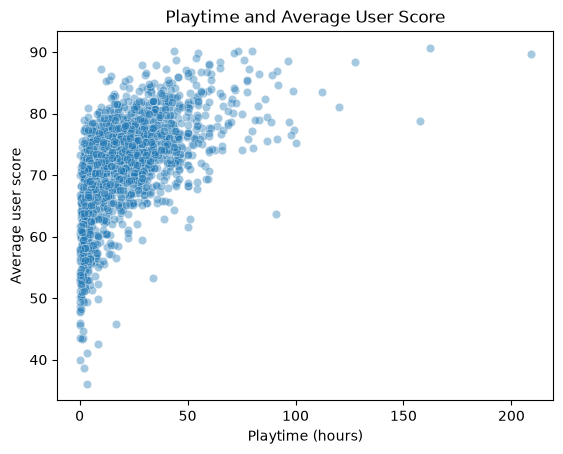

In [35]:
import seaborn as sns

playtime_data = playtime_data.copy()
playtime_data["length_hours"] = playtime_data["length_minutes"] / 60

ax = sns.scatterplot(data=playtime_data, x="length_hours", y="average", alpha=0.4)
ax.set(
    title="Playtime and Average User Score",
    xlabel="Playtime (hours)",
    ylabel="Average user score",
)

Figure 1. Visual novels with longer reported playtimes tended to have higher average user scores in this dataset.

Each point represents one visual novel with at least five playtime submissions. I used a scatter plot to see how playtime and average user score varied together. Most works were under 20 hours long, and relatively few were 60 hours or longer, so the pattern at the far right of the plot is harder to judge.

## Scores and Vote Counts by Tag

In [37]:
def tag_determine(work):
    """Return the qualifying study tags for one visual novel."""
    target_ids = ["g19", "g96", "g104"]
    tags_dict = {}
    for tag in work["tags"]:
        if (tag["id"] in target_ids
                and tag["rating"] >= 2
                and not tag["lie"]):
            if work["title"] not in tags_dict:
                tags_dict[work["title"]] = []
            tags_dict[work["title"]].append(tag["name"])
    return tags_dict

In [38]:
work = vn_data[vn_data["id"] == "v3"].iloc[0]
tag_determine(work)

{'Utawarerumono': ['Mystery', 'Comedy']}

In [39]:
tag_rows = []

for _, work in vn_data.iterrows():
    result = tag_determine(work)
    tag_names = result.get(work["title"], [])

    for tag_name in tag_names:
        tag_rows.append({
            "id": work["id"],
            "tag": tag_name,
            "average": work["average"],
            "votecount": work["votecount"]
        })

tag_data = pd.DataFrame(tag_rows)
tag_data.head()

,id,tag,average,votecount
0,v1,Comedy,57.8,693
1,v3,Mystery,78.2,6126
2,v3,Comedy,78.2,6126
3,v4,Romance,87.3,11607
4,v4,Comedy,87.3,11607


In [40]:
by_tag = tag_data.groupby("tag")

print(by_tag["id"].nunique())
by_tag[["average", "votecount"]].describe()

tag
Comedy      658
Mystery     315
Romance    1118
Name: id, dtype: int64


average                                                        \
          count       mean       std   min    25%    50%    75%   max   
tag                                                                     
Comedy    658.0  71.703951  5.948671  36.1  68.90  72.15  75.10  90.7   
Mystery   315.0  73.487302  7.078353  45.8  69.55  73.70  77.95  90.2   
Romance  1118.0  72.538909  5.595624  42.5  69.80  72.70  75.90  90.2   

        votecount                                                        \
            count         mean          std   min    25%    50%     75%   
tag                                                                       
Comedy      658.0   642.746201  1383.240484  50.0  82.25  164.5  515.00   
Mystery     315.0  1158.238095  2376.823896  50.0  97.00  198.0  883.00   
Romance    1118.0   593.813953  1498.935107  50.0  82.00  151.0  421.25   

                  
             max  
tag               
Comedy   13028.0  
Mystery  17220.0  
Romance  24657.0

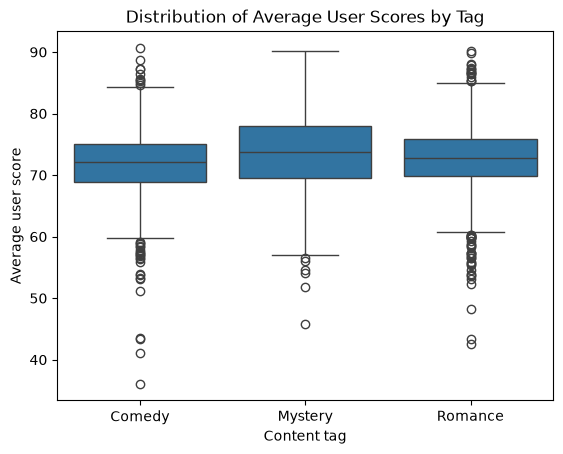

In [41]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots()
sns.boxplot(data=tag_data, x="tag", y="average", ax=ax)
ax.set(
    title="Distribution of Average User Scores by Tag",
    xlabel="Content tag",
    ylabel="Average user score",
)
plt.show()

Figure 2. Mystery-tagged works had a slightly higher median average user score than Comedy- or Romance-tagged works, and the three score distributions overlapped.

Each box shows the middle half of the scores for one tag, and the line inside marks the median. This makes it possible to compare both the typical score and the spread across groups. The median scores were 73.70 for Mystery, 72.15 for Comedy, and 72.70 for Romance. A work can appear in more than one group.